<a href="https://colab.research.google.com/github/michael-palomino-tm/Ingenier-a-de-Soluciones-con-Inteligencia-Artificial/blob/Mistral/3_1_2_Laboratorio_1_Observabilidad_Logs_MercadoAndes_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ISY0101 · Ingeniería de Soluciones con IA  
## EA3 · Actividad 1 — Laboratorio 1 (v3): instrumentación y logs estructurados

**Caso transversal:** MercadoAndes (datos ficticios).  
**Plataforma:** Google Colab o Jupyter.  
**Tiempo previsto:** 45 minutos (15 demostración, 20 práctica y 10 interpretación), más 20 minutos posteriores de discusión.

### Pregunta guía
> Si un agente responde de forma convincente, ¿cómo sabemos qué hizo, cuánto tardó, si falló una herramienta y si el LLM realmente respondió?

En esta versión distinguimos **respuesta real del LLM** y **respuesta didáctica simulada**. La simulación permite completar el laboratorio sin cuotas disponibles, pero **nunca se presenta como una llamada exitosa a Mistral**.

**Resultado:** tres escenarios registrados en JSONL, con `run_id`, modo de respuesta, errores y duraciones. **Alcance:** diapositivas 3–6 de 3.1.1; las trazas y métricas avanzadas corresponden a los laboratorios siguientes.

### Ruta de trabajo

1. Partimos de una aplicación simple que consulta **datos locales** y utiliza un **LLM** para redactar una respuesta.  
2. Instrumentamos la solicitud, las herramientas y la invocación al modelo.  
3. Ejecutamos tres escenarios: normal, lento y fallido.  
4. Examinamos eventos, duraciones y errores.  
5. Guardamos los resultados para reutilizar los criterios de prueba en los laboratorios 2 y 3.

**Alcance técnico:** la selección de la herramienta está controlada por el escenario, para que los fallos sean reproducibles. El LLM sintetiza la evidencia; por tanto, **no es un agente ReAct autónomo**. Esta simplificación es deliberada: aquí estudiamos observabilidad, no algoritmos de planificación.

## 1. Preparación del entorno (~5 min)

Instalamos LangChain, cliente OpenAI compatible con Mistral, y bibliotecas para analizar registros. Los datos empresariales están dentro del notebook.

**Seguridad:** en Colab, `LLM_API_KEY` se obtiene del panel **Secretos**. `LANGSMITH_API_KEY` no se utiliza en este laboratorio; se reservará para el laboratorio 2.

**Tres modos de funcionamiento** (se seleccionan en la próxima celda):

- `auto` (**predeterminado**): comprueba Mistral una sola vez y usa el respaldo simulado cuando no puede llamarlo. También cambia a respaldo si falla durante una solicitud, registrando el incidente.
- `real`: exige credencial y llamadas reales; una caída de Mistral se registra como error, sin generar una respuesta ficticia.
- `demo`: no llama a ninguna API; todas las respuestas y duraciones del LLM son didácticas y se identifican como simuladas.

**En clase:** usar `auto` para asegurar continuidad, pero comprobar en la salida cuál fue realmente el origen de cada respuesta.

In [19]:
# %pip instala dependencias dentro del entorno del notebook (Colab/Jupyter).
# langchain-openai permite conectar ChatOpenAI con la API compatible de Mistral.
# pandas analiza los eventos JSONL; matplotlib permite visualizar las duraciones.
%pip -q install "langchain-openai>=0.3,<2" "python-dotenv>=1,<2" pandas matplotlib

### 1.1 Configuración del LLM y sus secretos

Conservamos el patrón de la asignatura: `LLM_API_KEY`, `LLM_MODEL` y `LLM_BASE_URL`. No se muestra ninguna clave ni se conservan cuerpos HTTP de errores.

La configuración `ChatOpenAI(base_url="https://api.mistral.ai/v1")` utiliza el protocolo compatible con OpenAI, pero envía las solicitudes al servicio **Mistral**.

En modo `demo` no es necesario configurar `LLM_API_KEY`. En `auto`, su ausencia activa el respaldo didáctico. En `real` su ausencia es un error de configuración.

In [20]:
# PASO 1 — Cargar configuración y decidir el modo de ejecución.
# Ninguna clave debe escribirse literalmente en el notebook ni enviarse a logs.
# auto: usa Mistral si responde y, si falla, un respaldo didáctico identificado.
# real: solo solicitudes reales; demo: ninguna llamada externa al modelo.
import os
from dotenv import load_dotenv
load_dotenv()

# Cambia esta variable por "real" o "demo" si quieres forzar un comportamiento.
MODO_LLM = "auto"  # "auto" | "real" | "demo"
assert MODO_LLM in {"auto", "real", "demo"}

# Colab Secrets tiene prioridad sobre .env, como en los notebooks anteriores.
try:
    from google.colab import userdata
    clave_colab = userdata.get("LLM_API_KEY")
    _llm_model = userdata.get("LLM_MODEL_SMALL")
    _llm_base_url = userdata.get("LLM_BASE_URL")
except Exception:
    clave_colab = None

LLM_API_KEY = clave_colab or os.getenv("LLM_API_KEY")
LLM_MODEL = _llm_model or os.getenv("LLM_MODEL", "mistral-small-latest")
LLM_BASE_URL = _llm_base_url or os.getenv("LLM_BASE_URL", "https://api.mistral.ai/v1")

if MODO_LLM == "real" and not LLM_API_KEY:
    raise RuntimeError("Modo real: falta LLM_API_KEY en Colab Secrets o en .env.")

# Instanciar el cliente no consume tokens ni ejecuta ninguna petición.
from langchain_openai import ChatOpenAI
llm = None
if MODO_LLM != "demo" and LLM_API_KEY:
    llm = ChatOpenAI(
        model=LLM_MODEL,
        api_key=LLM_API_KEY,
        base_url=LLM_BASE_URL,
        temperature=0,
        timeout=25,
        max_retries=0,  # La prueba de conectividad y el registro controlan los fallos.
        use_responses_api=False,
    )

print("Proveedor configurado:", "Mistral" if llm else "solo simulación didáctica")
print("Modelo:", LLM_MODEL, "| Modo solicitado:", MODO_LLM)
print("Endpoint:", LLM_BASE_URL if llm else "no se utilizará")
print("Credencial:", "configurada (oculta)" if LLM_API_KEY else "no configurada")

Proveedor configurado: Mistral
Modelo: ministral-8b-latest | Modo solicitado: auto
Endpoint: https://api.mistral.ai/v1
Credencial: configurada (oculta)


### 1.2 Prueba de conectividad de bajo consumo

Antes de ejecutar los tres escenarios hacemos **una sola solicitud breve** a Mistral, cuando corresponde. La salida informa la categoría del problema sin imprimir el contenido bruto de la excepción (que podría incluir información de autenticación).

La prueba verifica conectividad **en ese momento**: no asegura que haya cuota para las solicitudes siguientes. Si el modo es `auto` y Mistral falla durante una ejecución, el sistema registrará `llm_error`, activará el respaldo y marcará la respuesta como **simulada**. Una caída de conexión no equivale a un error de planificación ni a una respuesta falsa del modelo.

In [21]:
# PASO 2 — Diagnosticar la disponibilidad del proveedor ANTES del laboratorio.
# La clasificación transforma excepciones técnicas en categorías comprensibles.
# Importante: el texto completo de una excepción de autenticación puede revelar
# información sensible; solo conservamos nombre de clase y código de estado.
# Categorías seguras: la clase de excepción y su código, nunca el texto HTTP bruto.
def clasificar_error_llm(exc):
    nombre = type(exc).__name__
    codigo = getattr(exc, "status_code", None)
    if codigo is None:
        respuesta = getattr(exc, "response", None)
        codigo = getattr(respuesta, "status_code", None)
    if codigo == 429 or "RateLimit" in nombre:
        categoria = "limite_de_uso_o_cuota"
    elif codigo in (401, 403) or "Authentication" in nombre or "Permission" in nombre:
        categoria = "autenticacion_o_permisos"
    elif codigo in (408, 504) or "Timeout" in nombre:
        categoria = "tiempo_de_espera"
    elif "Connection" in nombre or codigo in (502, 503):
        categoria = "conexion_o_servicio"
    else:
        categoria = "otro_error_llm"
    return {"categoria": categoria, "tipo_error": nombre, "codigo_http": codigo}

# Este estado permite evitar llamadas repetidas si el proveedor ya falló.
proveedor_disponible = False
modo_efectivo = "demo"
if MODO_LLM == "demo" or llm is None:
    print("Diagnóstico: modo de demostración. No se ha llamado a ningún LLM.")
else:
    try:
        # Mensaje mínimo: no usamos datos del caso ni volcamos secretos.
        prueba = llm.invoke("Responde únicamente OK.")
        proveedor_disponible = True
        modo_efectivo = "real"
        print("Diagnóstico: Mistral respondió correctamente. Modo efectivo: real.")
    except Exception as exc:
        diagnostico = clasificar_error_llm(exc)
        print("Diagnóstico de conexión (sin datos sensibles):", diagnostico)
        if MODO_LLM == "real":
            print("Modo real: las solicitudes que requieran Mistral reportarán el error.")
        else:
            print("Modo auto: se utilizará respaldo didáctico simulado, claramente identificado.")

print("Modo efectivo inicial:", modo_efectivo)

Diagnóstico: Mistral respondió correctamente. Modo efectivo: real.
Modo efectivo inicial: real


## 2. Datos y escenarios de MercadoAndes (~3 min)

Datos **ficticios**, idénticos en las tres modalidades (`real`, `auto`, `demo`):

- Ventas: 1.200 pedidos en el trimestre anterior y 1.020 en el actual.
- Reclamos: 230 en total, de ellos 138 por entregas tardías.
- Operación: demanda de 400 despachos por semana y capacidad de 320.

Los tres escenarios no cambian:

1. **Normal:** herramienta de ventas sin demora.
2. **Lento:** herramienta de operaciones con 2 segundos de espera artificial.
3. **Fallido:** fuente de reclamos que devuelve una excepción prevista.

Una coincidencia temporal entre ventas y reclamos **no demuestra causalidad**.

In [22]:
# PASO 3 — Definir un conjunto de datos estable para comparar ejecuciones.
# Todos los valores representan una empresa FICTICIA: no son estadísticas reales.
# Los escenarios controlan la herramienta, una espera artificial y un error.
# Datos didácticos, estables para las tres demostraciones.
DATOS = {
    "ventas": {"pedidos_trimestre_anterior": 1200, "pedidos_trimestre_actual": 1020,
               "abandono_carritos_pct": 32},
    "reclamos": {"total": 230, "entrega_tardia": 138, "producto": 46, "otros": 46},
    "operaciones": {"demanda_despachos_semanales": 400, "capacidad_semanal": 320,
                    "entregas_tardias_pct": 27},
}

# Tres escenarios: normal, retraso artificial y fallo artificial.
ESCENARIOS = {
    "normal": {"fuente": "ventas", "retraso": 0, "fallar": False},
    "lento": {"fuente": "operaciones", "retraso": 2, "fallar": False},
    "fallido": {"fuente": "reclamos", "retraso": 0, "fallar": True},
}

print("Fuentes disponibles:", list(DATOS))
print("Escenarios controlados:", list(ESCENARIOS))

Fuentes disponibles: ['ventas', 'reclamos', 'operaciones']
Escenarios controlados: ['normal', 'lento', 'fallido']


## 3. ¿Qué vamos a registrar? (~7 min)

Usamos JSONL: un objeto JSON por línea, con campos `timestamp`, `run_id`, `evento`, `estado`, `duracion_ms` y `metadata`.

**Novedad de v2:** las invocaciones reales tienen eventos `llm_start`/`llm_end`; las simulaciones se anotan como `llm_sim_start`/`llm_sim_end`. Si Mistral falla, queda `llm_error` y puede activarse una respuesta simulada **sin borrar ese error**.

`request_end` guarda además `modo_respuesta` (`real`, `simulado` o `ninguno`). Cuando es simulado, `estado` se marca `ok_simulado`, no `ok`. Los tokens solo se atribuyen al proveedor real; en simulación son `None`.

No almacenamos credenciales, prompts de personas reales, datos sensibles ni razonamientos privados del LLM.

In [23]:
# PASO 4 — Crear nuestro registrador común de eventos.
# JSONL = un objeto JSON completo por cada línea del archivo.
# run_id identifica una solicitud: sirve para relacionar sus distintos eventos.
# perf_counter() se reservará para duraciones; timestamp será fecha UTC.
import json
import time
import uuid
from datetime import datetime, timezone
from pathlib import Path

RUTA_LOGS = Path("/content/mercadoandes_lab1.jsonl") if Path("/content").exists() else Path("mercadoandes_lab1.jsonl")

# Reiniciar únicamente el archivo de este laboratorio para evitar resultados de pruebas previas.
RUTA_LOGS.write_text("", encoding="utf-8")
EVENTOS = []

def registrar(run_id, evento, estado, duracion_ms=None, **metadata):
    """Agrega un evento estructurado, tanto en memoria como en un archivo JSONL."""
    # Un mismo esquema facilita filtrar y analizar eventos de distintas fuentes.
    registro = {
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "run_id": run_id,
        "evento": evento,
        "estado": estado,
        "duracion_ms": round(duracion_ms, 2) if duracion_ms is not None else None,
        "metadata": metadata,
    }
    # Copia en memoria: facilita explorar registros sin volver a leer el archivo.
    EVENTOS.append(registro)
    # Modo "a": agrega una línea sin sobrescribir registros anteriores.
    with RUTA_LOGS.open("a", encoding="utf-8") as archivo:
        archivo.write(json.dumps(registro, ensure_ascii=False) + "\n")
    return registro

print("Archivo de logs:", RUTA_LOGS)

Archivo de logs: /content/mercadoandes_lab1.jsonl


### 3.1 Instrumentamos el acceso a herramientas

Una herramienta no solo entrega datos: también puede tardar demasiado o fallar. Registraremos ambos casos con el mismo identificador de solicitud (`run_id`).

La pausa de 2 segundos y el error del tercer escenario **son provocados deliberadamente**. Así sabemos qué esperamos observar y podemos contrastarlo con los logs.

In [24]:
# PASO 5 — Instrumentar las herramientas del caso.
# tool_start marca el inicio; tool_end confirma la finalización correcta.
# tool_error documenta el fallo y vuelve a lanzar la excepción hacia el flujo.
# La demora introducida aquí pertenece a la HERRAMIENTA, no a Mistral.
def consultar_fuente(fuente, run_id, retraso=0, fallar=False):
    """Consulta un conjunto local; puede simular lentitud o fallo para el laboratorio."""
    inicio = time.perf_counter()  # Reloj adecuado para medir intervalos.
    registrar(run_id, "tool_start", "inicio", herramienta=fuente)
    try:
        if retraso:
            time.sleep(retraso)  # Demora artificial de la herramienta, NO del LLM.
        if fallar:
            raise RuntimeError("Fallo didáctico: fuente temporalmente no disponible")
        if fuente not in DATOS:
            raise KeyError(f"Fuente desconocida: {fuente}")

        datos = DATOS[fuente].copy()
        registrar(run_id, "tool_end", "ok",
                 (time.perf_counter() - inicio) * 1000,
                 herramienta=fuente, campos=list(datos))
        return datos
    except Exception as exc:
        registrar(run_id, "tool_error", "error",
                 (time.perf_counter() - inicio) * 1000,
                 herramienta=fuente, tipo_error=type(exc).__name__,
                 mensaje=str(exc))
        raise

### 3.2 Instrumentamos Mistral y el respaldo didáctico

La respuesta **simulada** no representa inferencia real, consumo de tokens ni latencia del proveedor: es una plantilla local que se construye con las cifras ficticias. Se conserva la medición real del tiempo consumido por el código, pero la duración de una simulación **no se compara** con latencias de Mistral.

En modo `auto`, si una petición real falla registraremos primero `llm_error` (con categoría y código HTTP seguro, cuando esté disponible) y después `llm_sim_start`/`llm_sim_end`. En modo `real`, no se sustituye la respuesta.

In [25]:
# PASO 6 — Instrumentar las respuestas reales y las simuladas SIN confundirlas.
# Una respuesta simulada es texto producido por Python, NO por un modelo de IA.
# Por eso sus eventos terminan en llm_sim_end y los tokens quedan en None.
# Si la API real falla, registramos llm_error antes de utilizar un respaldo.
from langchain_core.messages import SystemMessage, HumanMessage

# Textos locales y deterministas: solo para practicar instrumentación sin API.
def redactar_simulado(fuente, datos):
    if fuente == "ventas":
        anterior, actual = datos["pedidos_trimestre_anterior"], datos["pedidos_trimestre_actual"]
        variacion = (actual - anterior) / anterior * 100
        return (f"[SIMULACIÓN DIDÁCTICA] Los pedidos pasaron de {anterior} a {actual} "
                f"({variacion:+.1f}%). El abandono de carritos alcanza "
                f"{datos['abandono_carritos_pct']}%. Estos datos no establecen la causa de la caída.")
    if fuente == "operaciones":
        return (f"[SIMULACIÓN DIDÁCTICA] La demanda semanal es {datos['demanda_despachos_semanales']} "
                f"y la capacidad {datos['capacidad_semanal']}; "
                f"{datos['entregas_tardias_pct']}% de entregas son tardías. "
                "Existe una brecha de capacidad; no puede atribuirse automáticamente la caída de ventas a ella.")
    return "[SIMULACIÓN DIDÁCTICA] Datos consultados correctamente; revisar evidencia."


def registrar_respuesta_simulada(fuente, datos, run_id, motivo):
    """Emite eventos que identifican sin ambigüedad el origen didáctico."""
    inicio = time.perf_counter()
    registrar(run_id, "llm_sim_start", "inicio", modo="simulado", motivo=motivo)
    texto = redactar_simulado(fuente, datos)
    registrar(run_id, "llm_sim_end", "ok_simulado", (time.perf_counter()-inicio)*1000,
             modo="simulado", motivo=motivo,
             input_tokens=None, output_tokens=None, total_tokens=None)
    return texto, "simulado"


def redactar_respuesta(fuente, datos, run_id):
    """Devuelve (texto, modo), preservando la evidencia de cualquier fallo real."""
    # Este estado compartido evita insistir con llamadas que ya fallaron.
    global proveedor_disponible
    if MODO_LLM == "demo" or (MODO_LLM == "auto" and not proveedor_disponible):
        motivo = "modo_demo" if MODO_LLM == "demo" else "proveedor_no_disponible"
        return registrar_respuesta_simulada(fuente, datos, run_id, motivo)
    if llm is None:
        raise RuntimeError("No existe cliente Mistral configurado para modo real")

    instrucciones = (
        "Eres un analista de MercadoAndes. Usa solo los datos entregados. "
        "Responde en español en máximo 90 palabras. Distingue hechos de hipótesis. "
        "No afirmes relaciones causales sin evidencia."
    )
    mensaje = f"Fuente: {fuente}. Datos: {json.dumps(datos, ensure_ascii=False)}. Resume los hallazgos."
    inicio = time.perf_counter()
    registrar(run_id, "llm_start", "inicio", modelo=LLM_MODEL, modo="real")
    try:
        respuesta = llm.invoke([SystemMessage(content=instrucciones), HumanMessage(content=mensaje)])
        # Metadatos proporcionados por la API: no estimamos tokens a mano.
        uso = respuesta.usage_metadata or {}
        registrar(run_id, "llm_end", "ok", (time.perf_counter()-inicio)*1000,
                 modelo=LLM_MODEL, modo="real",
                 input_tokens=uso.get("input_tokens"),
                 output_tokens=uso.get("output_tokens"),
                 total_tokens=uso.get("total_tokens"))
        contenido = respuesta.content if isinstance(respuesta.content, str) else str(respuesta.content)
        return contenido, "real"
    except Exception as exc:
        info = clasificar_error_llm(exc)
        # No guardar str(exc): algunos servicios incluyen fragmentos de credenciales.
        registrar(run_id, "llm_error", "error", (time.perf_counter()-inicio)*1000,
                 modelo=LLM_MODEL, modo="real", **info)
        # El fallback solo corresponde al modo auto; real conserva el error.
        if MODO_LLM == "auto":
            proveedor_disponible = False  # No insistir contra un límite de cuota.
            print("Mistral no disponible:", info["categoria"],
                  "| se activa respuesta SIMULADA para esta solicitud.")
            return registrar_respuesta_simulada(fuente, datos, run_id, "fallo_llm_real")
        raise

## 4. Flujo instrumentado

Una solicitud sigue `request_start → tool_start → tool_end → LLM → request_end`. En caso de fallo de herramienta, el LLM no se invoca. En caso de fallo del proveedor, la ejecución depende del modo seleccionado:

- `real`: `llm_error`, `request_end(error)`.
- `auto`: `llm_error` seguido de `llm_sim_*`, `request_end(ok_simulado)`.
- `demo`: solo `llm_sim_*`, `request_end(ok_simulado)`.

**Nunca interpretar `ok_simulado` como éxito de Mistral**.

In [26]:
# PASO 7 — Unir herramientas y LLM en una solicitud instrumentada.
# Cada ejecución genera un run_id nuevo y un request_start/request_end.
# El mismo run_id viaja a consultar_fuente() y redactar_respuesta().
# Un error de herramienta detiene el flujo antes de intentar llamar al LLM.
def ejecutar_escenario(nombre):
    """Ejecuta una solicitud y devuelve respuesta, origen y tiempo medido."""
    if nombre not in ESCENARIOS:
        raise ValueError("Escenario desconocido")
    config = ESCENARIOS[nombre]
    # Identificador único por solicitud para correlacionar todos sus pasos.
    run_id = uuid.uuid4().hex[:12]
    inicio = time.perf_counter()
    registrar(run_id, "request_start", "inicio", escenario=nombre, modo_configurado=MODO_LLM)
    try:
        datos = consultar_fuente(config["fuente"], run_id,
                                retraso=config["retraso"], fallar=config["fallar"])
        texto, modo = redactar_respuesta(config["fuente"], datos, run_id)
        duracion = (time.perf_counter()-inicio)*1000
        # Éxito técnico REAL y finalización SIMULADA son estados distintos.
        estado = "ok" if modo == "real" else "ok_simulado"
        registrar(run_id, "request_end", estado, duracion, escenario=nombre, modo_respuesta=modo)
        return {"run_id": run_id, "escenario": nombre, "estado": estado,
                "modo_respuesta": modo, "duracion_ms": round(duracion, 2), "respuesta": texto}
    except Exception as exc:
        duracion = (time.perf_counter()-inicio)*1000
        registrar(run_id, "request_end", "error", duracion,
                 escenario=nombre, modo_respuesta="ninguno", tipo_error=type(exc).__name__)
        return {"run_id": run_id, "escenario": nombre, "estado": "error",
                "modo_respuesta": "ninguno", "duracion_ms": round(duracion, 2),
                "respuesta": "No disponible", "tipo_error": type(exc).__name__}

## 5. Primera ejecución: escenario normal (~15 min)

Ejecutamos el caso normal. Además del `run_id`, verificamos el campo `modo_respuesta`: puede ser `real` o `simulado` según disponibilidad. Una respuesta didáctica incluye el prefijo **[SIMULACIÓN DIDÁCTICA]**.

Después mostramos los eventos correlacionados. Incluso sin API podremos mostrar la secuencia de herramientas y los registros estructurados.

In [27]:
# Ejecutar la solicitud NORMAL para observar el camino habitual del sistema.
# Estado ok = terminó con Mistral; ok_simulado = terminó con texto local.
# La duración reportada incluye la herramienta y la generación de respuesta.
resultado_normal = ejecutar_escenario("normal")
print("Estado:", resultado_normal["estado"])
print("Origen de respuesta:", resultado_normal["modo_respuesta"].upper())
print("ID:", resultado_normal["run_id"])
print("Duración (ms):", resultado_normal["duracion_ms"])
print("Respuesta:", resultado_normal["respuesta"])

Estado: ok
Origen de respuesta: REAL
ID: afef64904be8
Duración (ms): 1613.57
Respuesta: **Hechos:**
- Los pedidos cayeron de **1200** (trimestre anterior) a **1020** (actual), una reducción del **15%**.
- El abandono de carritos alcanzó el **32%** (sin contexto previo).

**Hipótesis (sin evidencia causal):**
- Posible pérdida de clientes o menor demanda.
- El alto abandono de carritos podría estar vinculado a la caída en ventas, pero no se confirma relación directa.

*Recomendación:* Analizar causas del abandono y comparar con métricas históricas.


In [28]:
# Ver únicamente los eventos de la solicitud normal.
# Otros run_id no pertenecen a esta ejecución, aunque compartan el archivo.
# Filtramos eventos por run_id: pertenecen a la misma solicitud.
for evento in EVENTOS:
    if evento["run_id"] == resultado_normal["run_id"]:
        print(evento["evento"], "|", evento["estado"], "|", evento["duracion_ms"], "ms")

request_start | inicio | None ms
tool_start | inicio | None ms
tool_end | ok | 0.12 ms
llm_start | inicio | None ms
llm_end | ok | 1612.31 ms
request_end | ok | 1613.57 ms


## 6. Práctica guiada: escenarios lento y fallido (~20 min)

**A. Lento:** la herramienta `operaciones` incorpora una demora artificial de aproximadamente 2.000 ms. Debe quedar registrada en `tool_end`, independientemente de que Mistral esté disponible.

**B. Fallido:** la herramienta `reclamos` genera `tool_error`. No debería aparecer ningún evento `llm_start` ni `llm_sim_start` para ese `run_id`.

**Atención:** si una consulta normal o lenta usa el respaldo, aparecerá `ok_simulado`; los tiempos de generación local no sirven para estimar el rendimiento de Mistral.

In [29]:
# Comparar dos situaciones controladas: herramienta lenta y herramienta fallida.
# La tabla muestra por separado estado, origen de respuesta y duración total.
resultado_lento = ejecutar_escenario("lento")
resultado_fallido = ejecutar_escenario("fallido")

for resultado in (resultado_normal, resultado_lento, resultado_fallido):
    print(f"{resultado['escenario']:8s} | {resultado['estado']:12s} | "
          f"origen={resultado['modo_respuesta']:8s} | "
          f"{resultado['duracion_ms']:9.1f} ms | run_id={resultado['run_id']}")

normal   | ok           | origen=real     |    1613.6 ms | run_id=afef64904be8
lento    | ok           | origen=real     |    3266.6 ms | run_id=88d8ea969f05
fallido  | error        | origen=ninguno  |       0.3 ms | run_id=441fe588fa0d


### 6.1 Leer los logs y separar sus orígenes

Pandas permite verificar la secuencia y comparar duraciones. **Separamos los resultados reales de los simulados** antes de interpretar el rendimiento del proveedor.

El escenario lento mide el retraso artificial de la herramienta; para medir latencia real del LLM es imprescindible disponer de un evento `llm_end` con `modo=real`.

In [30]:
# Leer JSONL como tabla: Pandas interpreta una línea como un registro.
# metadata contiene campos específicos de cada tipo de evento.
# Solo llm_end aporta consumo de tokens reales; no atribuir tokens a simulaciones.
import pandas as pd

df_logs = pd.read_json(RUTA_LOGS, lines=True)
display(df_logs[["run_id", "evento", "estado", "duracion_ms", "metadata"]])

resumen = df_logs[df_logs["evento"] == "request_end"].copy()
resumen["escenario"] = resumen["metadata"].apply(lambda m: m.get("escenario"))
resumen["modo_respuesta"] = resumen["metadata"].apply(lambda m: m.get("modo_respuesta"))
display(resumen[["run_id", "escenario", "modo_respuesta", "estado", "duracion_ms"]])

# La tabla de tokens NO mezcla estimaciones o ceros con medidas reales.
llm_reales = df_logs[df_logs["evento"] == "llm_end"].copy()
if llm_reales.empty:
    print("Sin llamadas reales exitosas: no hay datos de consumo de tokens de Mistral.")
else:
    print("Tokens reportados por el proveedor en llamadas reales:")
    display(llm_reales[["run_id", "duracion_ms", "metadata"]])

,run_id,evento,estado,duracion_ms,metadata
0,afef64904be8,request_start,inicio,NaN,"{'escenario': 'normal', 'modo_configurado': 'a..."
1,afef64904be8,tool_start,inicio,NaN,{'herramienta': 'ventas'}
2,afef64904be8,tool_end,ok,0.12,"{'herramienta': 'ventas', 'campos': ['pedidos_..."
3,afef64904be8,llm_start,inicio,NaN,"{'modelo': 'ministral-8b-latest', 'modo': 'real'}"
4,afef64904be8,llm_end,ok,1612.31,"{'modelo': 'ministral-8b-latest', 'modo': 'rea..."
5,afef64904be8,request_end,ok,1613.57,"{'escenario': 'normal', 'modo_respuesta': 'real'}"
6,88d8ea969f05,request_start,inicio,NaN,"{'escenario': 'lento', 'modo_configurado': 'au..."
7,88d8ea969f05,tool_start,inicio,NaN,{'herramienta': 'operaciones'}
8,88d8ea969f05,tool_end,ok,2000.41,"{'herramienta': 'operaciones', 'campos': ['dem..."
9,88d8ea969f05,llm_start,inicio,NaN,"{'modelo': 'ministral-8b-latest', 'modo': 'real'}"


,run_id,escenario,modo_respuesta,estado,duracion_ms
5,afef64904be8,normal,real,ok,1613.57
11,88d8ea969f05,lento,real,ok,3266.57
15,441fe588fa0d,fallido,ninguno,error,0.31


Tokens reportados por el proveedor en llamadas reales:


,run_id,duracion_ms,metadata
4,afef64904be8,1612.31,"{'modelo': 'ministral-8b-latest', 'modo': 'rea..."
10,88d8ea969f05,1263.39,"{'modelo': 'ministral-8b-latest', 'modo': 'rea..."


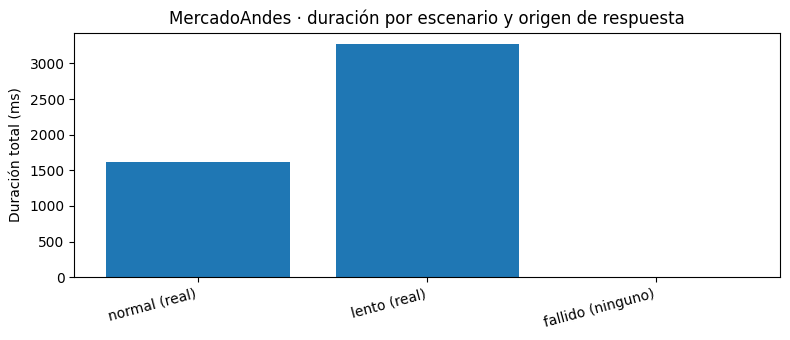

In [31]:
# Construir un gráfico exploratorio de tiempos totales por ejecución.
# Interpretar junto al origen: los tiempos simulados no son latencia de Mistral.
# El escenario fallido puede ser breve precisamente porque corta el flujo.
import matplotlib.pyplot as plt

# Muestra todas las solicitudes, pero distingue visualmente el origen en etiquetas.
# No equiparar la latencia de respuesta local con la del modelo remoto.
etiquetas = [f"{fila.escenario} ({fila.modo_respuesta})" for fila in resumen.itertuples()]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(etiquetas, resumen["duracion_ms"])
ax.set_ylabel("Duración total (ms)")
ax.set_title("MercadoAndes · duración por escenario y origen de respuesta")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 7. Análisis de resultados en equipos (~10 min)

Responde usando la evidencia del JSONL:

1. **Correlación:** ¿qué eventos comparten el mismo `run_id`?
2. **Lentitud:** ¿qué registro confirma los 2.000 ms de demora artificial y por qué no es latencia del LLM?
3. **Fallo:** ¿qué eventos dejan de existir después de `tool_error`?
4. **Origen:** ¿qué diferencia hay entre `llm_end` y `llm_sim_end`? ¿Qué significa `ok_simulado`?
5. **Límite de uso:** si aparece `llm_error`, ¿qué categoría segura permite diagnosticarlo sin divulgar la clave?
6. **Calidad:** ¿podemos concluir que una respuesta es correcta solo porque un registro dice `ok`? ¿Y si dice `ok_simulado`?
7. **Privacidad y evidencia:** ¿qué información nunca deberíamos registrar? ¿Los datos disponibles permiten atribuir causalidad?

**Producto:** tres ejecuciones, un JSONL, resumen con estado y modo de respuesta, y 3–5 líneas de diagnóstico con referencias a eventos concretos.

## 8. Guardar evidencia

El archivo `mercadoandes_lab1.jsonl` conserva exactamente lo ocurrido en esta sesión. El laboratorio 2 reutilizará el caso, pero podrá ejecutarse independientemente de este entorno.

**No publicar registros que contengan secretos o datos reales sensibles.** Si compartes el JSONL, comprueba que no incluya mensajes HTTP, prompts privados ni identificadores de personas.

In [32]:
# Verificar evidencia y totales antes de guardar el archivo.
# La cantidad de llm_end puede ser cero si se usó el respaldo didáctico.
# No se debe interpretar ese cero como "cero tokens consumidos" por Mistral.
print("Evidencia generada:", RUTA_LOGS.resolve())
print("Eventos registrados:", len(EVENTOS))
print("Solicitudes finalizadas:", int((df_logs["evento"] == "request_end").sum()))
print("Llamadas reales exitosas:", int((df_logs["evento"] == "llm_end").sum()))
print("Respuestas didácticas:", int((df_logs["evento"] == "llm_sim_end").sum()))

# En Google Colab, descomenta para descargar el archivo:
# from google.colab import files
# files.download(str(RUTA_LOGS))

Evidencia generada: /content/mercadoandes_lab1.jsonl
Eventos registrados: 16
Solicitudes finalizadas: 3
Llamadas reales exitosas: 2
Respuestas didácticas: 0
